RQ1 summary not found; using /Users/ivan/Desktop/Paper Results/RQ1/runs.csv


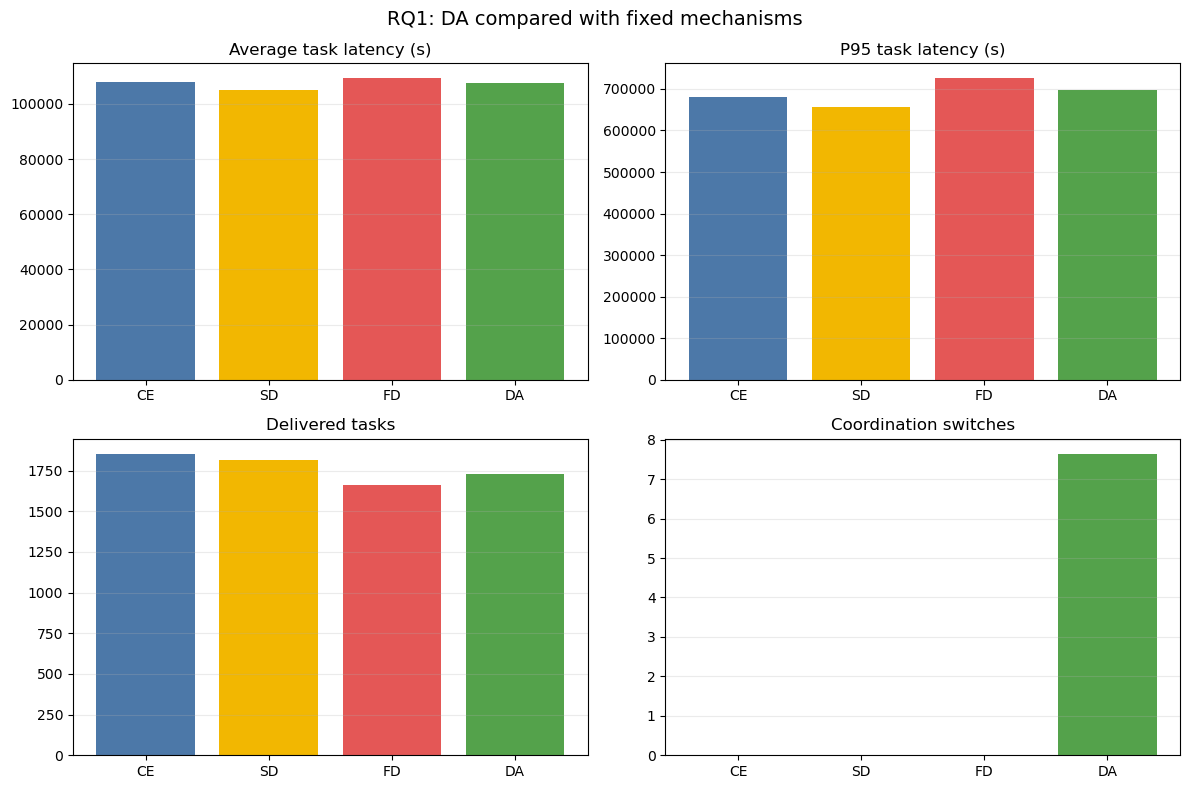

,coord_label,created_mean,created_std,created_min,created_max,created_count,delivered_mean,delivered_std,delivered_min,delivered_max,...,wall_time_s_mean,wall_time_s_std,wall_time_s_min,wall_time_s_max,wall_time_s_count,event_count_mean,event_count_std,event_count_min,event_count_max,event_count_count
0,CE,22564.520370,4764.129805,16912,29206,540,1852.361111,1289.502149,489,5376,...,43.496491,23.415659,15.231204,126.678457,540,90188.494444,34412.522613,43129.0,177205.0,540
3,SD,22550.646296,4745.596127,16858,29337,540,1813.662963,1226.629007,504,5189,...,40.390603,21.114261,14.972593,113.157240,539,87060.198516,30620.547593,43125.0,174239.0,539
2,FD,22563.672222,4762.864304,16899,29322,540,1660.142593,1042.766783,485,4425,...,36.473152,18.517835,14.753286,95.132641,540,74510.340741,23227.136272,43045.0,137834.0,540
1,DA,22563.118519,4751.785838,16982,29270,540,1727.662963,1128.296694,481,5209,...,49.803125,21.512276,17.959325,122.010719,540,79953.801852,26516.508012,42922.0,166588.0,540


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_ROOT_OVERRIDE = None  # Example: Path('/Users/ivan/Desktop/Paper Results')


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))

# RQ1 - Dynamic Adaptation vs fixed coordination mechanisms

def mechanism_summary_from_runs(runs_path):
    runs = pd.read_csv(runs_path)
    if 'status' in runs.columns:
        runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
    metrics = [
        'created', 'delivered', 'expired', 'pending', 'failed', 'recovered',
        'success_rate', 'completion_rate', 'throughput_per_hour',
        'avg_latency_s', 'median_latency_s', 'p95_latency_s', 'max_latency_s',
        'switch_count', 'fd_switch_count', 'sd_switch_count', 'ce_switch_count',
        'adapt_checks', 'adapt_overhead_ms_mean', 'rtlola_query_ms_mean',
        'scoring_ms_mean', 'wall_time_s', 'event_count',
    ]
    metrics = [metric for metric in metrics if metric in runs.columns]
    for metric in metrics:
        runs[metric] = pd.to_numeric(runs[metric], errors='coerce')
    summary = runs.groupby('coord_label', dropna=False)[metrics].agg(['mean', 'std', 'min', 'max', 'count'])
    summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
    return summary.reset_index()


ROOT = find_results_root(required_any=[Path('RQ1/summary_by_mechanism.csv'), Path('RQ1/runs.csv')])
rq1_dir = ROOT / 'RQ1'
summary_path = rq1_dir / 'summary_by_mechanism.csv'
runs_path = rq1_dir / 'runs.csv'

if summary_path.exists():
    df = pd.read_csv(summary_path)
elif runs_path.exists():
    print(f'RQ1 summary not found; using {runs_path}')
    df = mechanism_summary_from_runs(runs_path)
else:
    raise FileNotFoundError(f'Neither {summary_path} nor {runs_path} exists')

order = ['CE', 'SD', 'FD', 'DA']
df['coord_label'] = pd.Categorical(df['coord_label'], categories=order, ordered=True)
df = df.sort_values('coord_label')
plots = [
    ('avg_latency_s_mean', 'Average task latency (s)'),
    ('p95_latency_s_mean', 'P95 task latency (s)'),
    ('delivered_mean', 'Delivered tasks'),
    ('switch_count_mean', 'Coordination switches'),
]
missing = [metric for metric, _ in plots if metric not in df.columns]
if missing:
    raise KeyError(f'Missing RQ1 metrics: {missing}')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = {'CE': '#4C78A8', 'SD': '#F2B701', 'FD': '#E45756', 'DA': '#54A24B'}
for ax, (metric, title) in zip(axes.flat, plots):
    labels = df['coord_label'].astype(str)
    ax.bar(labels, pd.to_numeric(df[metric], errors='coerce'), color=[colors.get(x, '#999999') for x in labels])
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('RQ1: DA compared with fixed mechanisms', fontsize=14)
fig.tight_layout()
plt.show()
display(df)


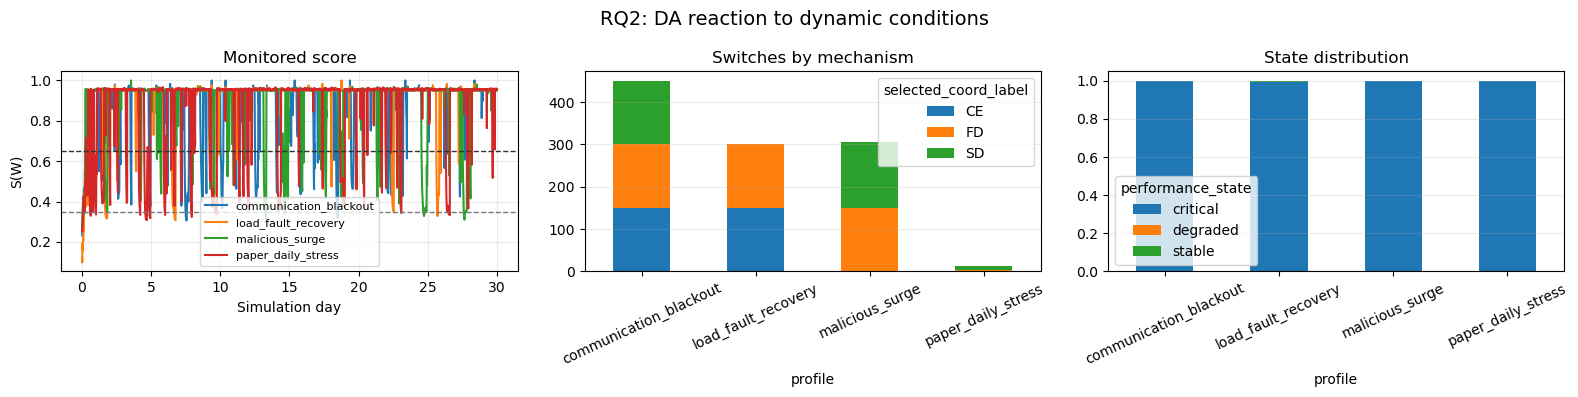

,profile,coord_label,runs,created_mean,created_std,created_p95,delivered_mean,delivered_std,delivered_p95,pending_mean,...,p95_latency_s_p95,switch_count_mean,switch_count_std,switch_count_p95,adapt_checks_mean,adapt_checks_std,adapt_checks_p95,adapt_overhead_ms_mean_mean,adapt_overhead_ms_mean_std,adapt_overhead_ms_mean_p95
0,communication_blackout,DA,5,22459.2,155.144127,22691.0,11261.0,122.030734,11391.0,11198.2,...,2.716024e+05,90.0,0.000000,90.0,4035.4,5.504544,4042.0,0.454491,0.072285,0.531611
1,load_fault_recovery,DA,5,22148.8,110.064527,22324.0,15620.0,84.219950,15731.0,6528.8,...,1.193239e+06,60.4,0.894427,62.0,4053.8,3.898718,4059.0,0.433743,0.106427,0.589321
2,malicious_surge,DA,5,24085.6,128.900349,24236.0,5498.2,78.004487,5625.0,18587.4,...,1.283193e+06,61.2,0.447214,62.0,4025.8,5.263079,4032.0,0.425507,0.028029,0.456683
3,paper_daily_stress,DA,5,21515.0,109.947715,21651.0,1531.0,36.352441,1586.0,19984.0,...,6.256537e+05,2.6,0.894427,3.0,3975.6,4.929503,3982.0,0.738200,0.167447,0.890676


In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_ROOT_OVERRIDE = None  # Example: Path('/Users/ivan/Desktop/Paper Results')


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))

# RQ2 - DA reaction to evolving operating conditions
ROOT = find_results_root(required_all=[Path('RQ2/adaptation_state_timeseries.csv')])
rq2 = ROOT / 'RQ2'
timeseries_path = rq2 / 'adaptation_state_timeseries.csv'
switch_path = rq2 / 'switch_timeline.csv'

states = pd.read_csv(timeseries_path)
switches = pd.read_csv(switch_path) if switch_path.exists() else pd.DataFrame()
for col in ['sim_time', 'performance_score', 'score_latency', 'score_pending', 'score_failure', 'score_message_loss']:
    if col in states:
        states[col] = pd.to_numeric(states[col], errors='coerce')
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
first_runs = states.sort_values(['profile', 'run_id']).groupby('profile')['run_id'].first()
for profile, run_id in first_runs.items():
    data = states[states['run_id'] == run_id].sort_values('sim_time')
    axes[0].plot(data['sim_time'] / 86400, data['performance_score'], label=profile)
axes[0].axhline(0.35, color='#777777', linestyle='--', linewidth=1)
axes[0].axhline(0.65, color='#333333', linestyle='--', linewidth=1)
axes[0].set_title('Monitored score')
axes[0].set_xlabel('Simulation day')
axes[0].set_ylabel('S(W)')
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)
if switches.empty:
    axes[1].text(0.5, 0.5, 'No switches recorded', ha='center', va='center')
    axes[1].set_axis_off()
else:
    pivot = switches.pivot_table(index='profile', columns='selected_coord_label', values='switch_idx', aggfunc='count', fill_value=0)
    pivot.plot(kind='bar', stacked=True, ax=axes[1])
    axes[1].set_title('Switches by mechanism')
    axes[1].tick_params(axis='x', rotation=25)
    axes[1].grid(axis='y', alpha=0.25)
state_frac = states.pivot_table(index='profile', columns='performance_state', values='sim_time', aggfunc='count', fill_value=0)
state_frac = state_frac.div(state_frac.sum(axis=1), axis=0)
state_frac.plot(kind='bar', stacked=True, ax=axes[2])
axes[2].set_title('State distribution')
axes[2].tick_params(axis='x', rotation=25)
axes[2].grid(axis='y', alpha=0.25)
fig.suptitle('RQ2: DA reaction to dynamic conditions', fontsize=14)
fig.tight_layout()
plt.show()
display(pd.read_csv(rq2 / 'summary_by_profile.csv') if (rq2 / 'summary_by_profile.csv').exists() else states.head())


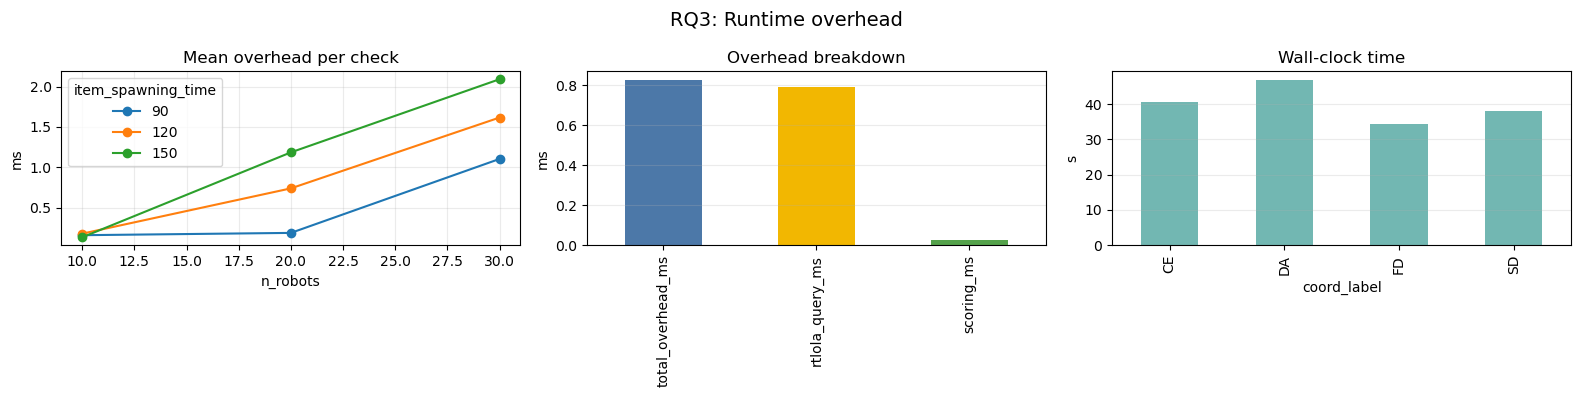

,coord_label,architecture,item_spawning_time,n_robots,runs,wall_time_s_mean,wall_time_s_std,wall_time_s_p95,event_count_mean,event_count_std,...,scoring_ms_mean_p95,adapt_overhead_wall_pct_mean,adapt_overhead_wall_pct_std,adapt_overhead_wall_pct_p95,trace_size_mb_mean,trace_size_mb_std,trace_size_mb_p95,overhead_trace_size_mb_mean,overhead_trace_size_mb_std,overhead_trace_size_mb_p95
0,CE,centralized-impprox,120,10,5,25.021967,0.392354,25.675002,53298.6,414.519360,...,NaN,0.000000,0.000000,0.000000,1.833210,0.012221,1.844071,0.000000,0.000000,0.000000
1,CE,centralized-impprox,120,20,5,39.506126,0.820839,40.925709,82424.4,265.835099,...,NaN,0.000000,0.000000,0.000000,2.767059,0.012811,2.783414,0.000000,0.000000,0.000000
2,CE,centralized-impprox,120,30,5,48.804707,0.809371,49.887626,107266.0,130.368708,...,NaN,0.000000,0.000000,0.000000,3.528379,0.006525,3.535595,0.000000,0.000000,0.000000
3,CE,centralized-impprox,150,10,5,19.425848,0.435844,19.836904,48802.8,478.055122,...,NaN,0.000000,0.000000,0.000000,1.656240,0.014778,1.672723,0.000000,0.000000,0.000000
4,CE,centralized-impprox,150,20,5,28.769646,0.611115,29.462702,75321.2,459.417784,...,NaN,0.000000,0.000000,0.000000,2.494936,0.015193,2.518649,0.000000,0.000000,0.000000
5,CE,centralized-impprox,150,30,5,35.426082,0.690484,36.079353,97040.0,331.942766,...,NaN,0.000000,0.000000,0.000000,3.166268,0.014247,3.179805,0.000000,0.000000,0.000000
6,CE,centralized-impprox,90,10,5,33.506808,0.805113,34.384830,60181.0,361.304581,...,NaN,0.000000,0.000000,0.000000,2.109899,0.011578,2.126733,0.000000,0.000000,0.000000
7,CE,centralized-impprox,90,20,5,61.662226,2.026113,64.289989,91626.6,293.878887,...,NaN,0.000000,0.000000,0.000000,3.122566,0.011205,3.138755,0.000000,0.000000,0.000000
8,CE,centralized-impprox,90,30,5,73.074598,2.183112,75.445533,119901.2,459.042700,...,NaN,0.000000,0.000000,0.000000,4.010641,0.014787,4.028978,0.000000,0.000000,0.000000
9,DA,dynamic-adaptation,120,10,5,29.424097,1.001573,30.875196,53178.4,159.633330,...,0.025987,2.308337,0.686573,3.334224,1.833630,0.009532,1.843766,1.441258,0.002506,1.444905


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_ROOT_OVERRIDE = None  # Example: Path('/Users/ivan/Desktop/Paper Results')


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))

# RQ3 - Runtime overhead of monitoring and adaptation
ROOT = find_results_root(required_all=[Path('RQ3/overhead_summary.csv')])
rq3 = ROOT / 'RQ3'
summary_path = rq3 / 'overhead_summary.csv'
wall_path = rq3 / 'wall_time_summary.csv'
samples_path = rq3 / 'overhead_samples.csv'

summary = pd.read_csv(summary_path)
wall = pd.read_csv(wall_path) if wall_path.exists() else pd.DataFrame()
samples = pd.read_csv(samples_path) if samples_path.exists() else pd.DataFrame()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
da = summary[summary['coord_label'] == 'DA']
if not da.empty and 'adapt_overhead_ms_mean_mean' in da:
    da.pivot_table(index='n_robots', columns='item_spawning_time', values='adapt_overhead_ms_mean_mean').plot(marker='o', ax=axes[0])
    axes[0].set_title('Mean overhead per check')
    axes[0].set_ylabel('ms')
    axes[0].grid(alpha=0.25)
if not samples.empty:
    samples[['total_overhead_ms', 'rtlola_query_ms', 'scoring_ms']].apply(pd.to_numeric, errors='coerce').mean().plot(kind='bar', ax=axes[1], color=['#4C78A8', '#F2B701', '#54A24B'])
    axes[1].set_title('Overhead breakdown')
    axes[1].set_ylabel('ms')
    axes[1].grid(axis='y', alpha=0.25)
if not wall.empty and 'wall_time_s_mean' in wall:
    wall.plot(x='coord_label', y='wall_time_s_mean', kind='bar', ax=axes[2], legend=False, color='#72B7B2')
    axes[2].set_title('Wall-clock time')
    axes[2].set_ylabel('s')
    axes[2].grid(axis='y', alpha=0.25)
fig.suptitle('RQ3: Runtime overhead', fontsize=14)
fig.tight_layout()
plt.show()
display(summary)


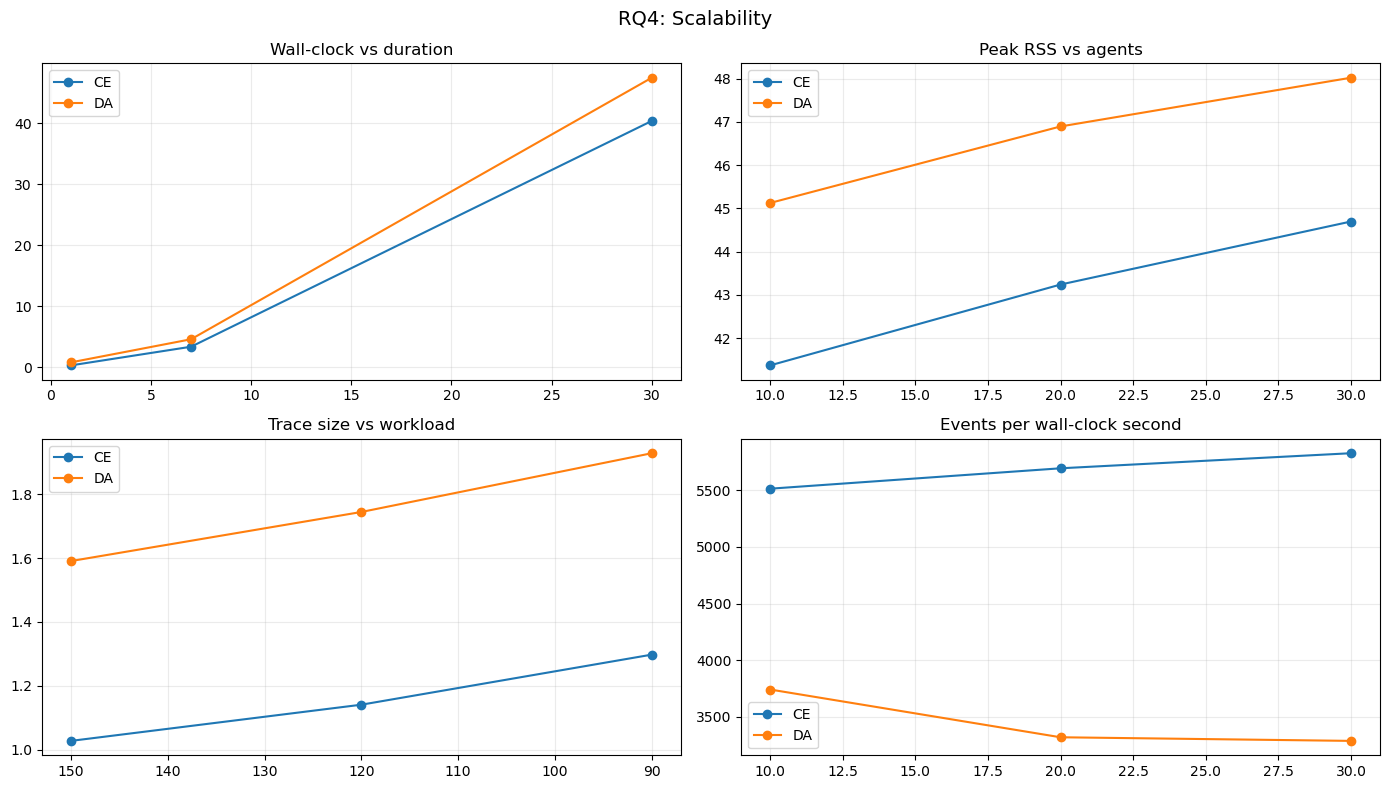

,coord_label,architecture,sim_days,item_spawning_time,n_robots,runs,wall_time_s_mean,wall_time_s_std,wall_time_s_p95,event_count_mean,...,delivered_p95,avg_latency_s_mean,avg_latency_s_std,avg_latency_s_p95,p95_latency_s_mean,p95_latency_s_std,p95_latency_s_p95,adapt_checks_mean,adapt_checks_std,adapt_checks_p95
0,CE,centralized-impprox,1,120,10,5,0.206689,0.010344,0.222034,1771.4,...,36.0,6211.610265,2427.349073,10040.161576,2.704157e+04,15108.748601,5.224169e+04,0.0,0.000000,0.0
1,CE,centralized-impprox,1,120,20,5,0.294385,0.009078,0.305168,2765.0,...,59.0,3465.983215,585.910712,4014.532244,2.551482e+04,5980.311975,3.556136e+04,0.0,0.000000,0.0
2,CE,centralized-impprox,1,120,30,5,0.384326,0.010373,0.396866,3623.2,...,68.0,3949.438860,1302.996167,5276.731214,2.328351e+04,11784.020878,4.387998e+04,0.0,0.000000,0.0
3,CE,centralized-impprox,1,150,10,5,0.179171,0.007177,0.185669,1622.0,...,32.0,8591.629222,3391.939228,12501.777699,3.945516e+04,12579.919429,5.162748e+04,0.0,0.000000,0.0
4,CE,centralized-impprox,1,150,20,5,0.269440,0.009534,0.278847,2592.6,...,45.0,3090.193794,1036.263612,4553.692900,1.593731e+04,4549.300405,2.198540e+04,0.0,0.000000,0.0
5,CE,centralized-impprox,1,150,30,5,0.327282,0.009284,0.336668,3167.0,...,59.0,3336.841278,924.979388,4904.275240,1.845590e+04,5941.619126,2.537997e+04,0.0,0.000000,0.0
6,CE,centralized-impprox,1,90,10,5,0.248198,0.003977,0.253071,2037.4,...,29.0,3463.761876,989.486262,4626.731302,1.780237e+04,8543.441496,3.151613e+04,0.0,0.000000,0.0
7,CE,centralized-impprox,1,90,20,5,0.344890,0.007430,0.353460,3099.6,...,72.0,4220.166758,1627.303602,5914.333820,1.928198e+04,8197.795164,3.097966e+04,0.0,0.000000,0.0
8,CE,centralized-impprox,1,90,30,5,0.445098,0.006384,0.451859,4011.0,...,84.0,2198.266650,685.459825,3256.311595,1.348167e+04,2295.859602,1.571578e+04,0.0,0.000000,0.0
9,CE,centralized-impprox,30,120,10,5,24.835304,0.234642,25.171150,53520.4,...,931.0,232072.123243,22633.242792,268736.961299,1.498480e+06,68113.930104,1.609650e+06,0.0,0.000000,0.0


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_ROOT_OVERRIDE = None  # Example: Path('/Users/ivan/Desktop/Paper Results')


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))

# RQ4 - Practical scalability limits
ROOT = find_results_root(required_all=[Path('RQ4/scalability_summary.csv')])
summary_path = ROOT / 'RQ4' / 'scalability_summary.csv'

df = pd.read_csv(summary_path)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for coord, data in df.groupby('coord_label'):
    wall = data.groupby('sim_days')['wall_time_s_mean'].mean().reset_index()
    axes[0, 0].plot(wall['sim_days'], wall['wall_time_s_mean'], marker='o', label=coord)
    rss = data.groupby('n_robots')['max_rss_mb_mean'].mean().reset_index()
    axes[0, 1].plot(rss['n_robots'], rss['max_rss_mb_mean'], marker='o', label=coord)
    trace = data.groupby('item_spawning_time')['total_output_size_mb_mean'].mean().reset_index().sort_values('item_spawning_time')
    axes[1, 0].plot(trace['item_spawning_time'], trace['total_output_size_mb_mean'], marker='o', label=coord)
    thr = data.groupby('n_robots')['events_per_wall_s_mean'].mean().reset_index()
    axes[1, 1].plot(thr['n_robots'], thr['events_per_wall_s_mean'], marker='o', label=coord)
axes[0, 0].set_title('Wall-clock vs duration')
axes[0, 1].set_title('Peak RSS vs agents')
axes[1, 0].set_title('Trace size vs workload')
axes[1, 0].invert_xaxis()
axes[1, 1].set_title('Events per wall-clock second')
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle('RQ4: Scalability', fontsize=14)
fig.tight_layout()
plt.show()
display(df)
